# 05: Forecasting Models

## Goal
Build forecasting approaches that beat the baselines from Notebook 04, adding them one at a time and keeping each only if it improves on what came before.

## The bar to beat (validation weeks, share of ICU beds in use)
| Weeks ahead | Best baseline | Error (points) |
|---|---|---|
| 1 | Same as this week | 0.93 |
| 2 | Same as this week | 1.05 |
| 3 | Same as this week | 1.27 |
| 4 | Same as this week | 1.30 |

Notebook 04 found that each baseline has half of what a good forecast needs: "same as this week" knows the current level but not the season, and "same as last year" knows the season but copies one year's exact peak. The clearest room for improvement is 3 to 4 weeks ahead in winter.

## How every approach is scored
All approaches use the shared backtest in `src/backtesting.py`, the same logic used for the baselines in Notebook 04. Only validation weeks (November 2024 to March 2026) are scored here. The holdout weeks (April to September 2026) are set aside for the final evaluation.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.backtesting import (
    load_icu_weekly,
    run_backtest,
    validation_results,
    score_by_horizon,
    compare_with_baselines,
    improvement_uncertainty,
    forecast_same_as_this_week,
    forecast_same_as_last_year,
)

icu_weekly = load_icu_weekly()

baseline_backtests = pd.concat(
    [
        run_backtest(icu_weekly, forecast_same_as_this_week, "Same as this week"),
        run_backtest(icu_weekly, forecast_same_as_last_year, "Same as last year"),
    ],
    ignore_index=True,
)
baseline_scores = score_by_horizon(validation_results(baseline_backtests))
print("Baseline scores on validation weeks (should match Notebook 04):")
print(baseline_scores[["avg_error_share_pts", "avg_error_patients"]].to_string())

Baseline scores on validation weeks (should match Notebook 04):
                                 avg_error_share_pts  avg_error_patients
rule              horizon_weeks                                         
Same as last year 1                             1.47              197.38
                  2                             1.49              202.69
                  3                             1.48              205.75
                  4                             1.50              211.44
Same as this week 1                             0.93              168.77
                  2                             1.05              197.39
                  3                             1.27              213.18
                  4                             1.30              224.07


## Approach 1: current level plus the usual seasonal change

**Idea:** combine what each baseline does well. Start from the share this week, then add how much the share usually changes over the same weeks of the year.

**Method:** to forecast from a given week to a target week h weeks later, look back at each earlier year and measure how much the share changed between the same two calendar weeks. Average those past changes and add the result to this week's share. For example, a forecast made in mid-December for mid-January adds the typical December-to-January rise.

Only weeks available at the forecast origin are used, and any past change involving a flagged 2024 week is skipped.

**Two versions, to test the question raised in Notebook 03:**
- **All past years:** averages changes from every earlier year, including 2020 to 2022.
- **Since 2023 only:** averages changes only from 2023 onward, leaving out the large swings of the COVID-19 years.

Both use ranges built from their own past errors, as in Notebook 04.

In [3]:
def make_seasonal_change_rule(use_changes_since=None):
    def forecast_current_plus_seasonal_change(origin_week, target_week, history):
        indexed_history = history.set_index("week_ending")
        share_by_week = indexed_history["icu_occupancy_share_pct"]
        is_flagged_by_week = indexed_history["is_voluntary_reporting_week"]
        current_share = share_by_week.iloc[-1]

        past_changes = []
        for years_back in range(1, 7):
            past_origin = origin_week - pd.Timedelta(weeks=52 * years_back)
            past_target = target_week - pd.Timedelta(weeks=52 * years_back)
            if past_origin not in share_by_week.index or past_target not in share_by_week.index:
                continue
            if is_flagged_by_week[past_origin] or is_flagged_by_week[past_target]:
                continue
            if use_changes_since is not None and past_origin < pd.Timestamp(use_changes_since):
                continue
            past_changes.append(share_by_week[past_target] - share_by_week[past_origin])

        if not past_changes:
            return current_share
        return current_share + np.mean(past_changes)

    return forecast_current_plus_seasonal_change


seasonal_backtests = pd.concat(
    [
        run_backtest(icu_weekly, make_seasonal_change_rule(), "Seasonal change (all past years)"),
        run_backtest(icu_weekly, make_seasonal_change_rule("2023-01-01"), "Seasonal change (since 2023)"),
    ],
    ignore_index=True,
)
seasonal_scores = score_by_horizon(validation_results(seasonal_backtests))
print("Approach 1 scores on validation weeks:")
print(seasonal_scores.to_string())
print()
print("Error in share (points) compared with the best baseline:")
print(compare_with_baselines(seasonal_scores, baseline_scores, "avg_error_share_pts").to_string())
print()
print("Error in patients compared with the best baseline:")
print(compare_with_baselines(seasonal_scores, baseline_scores, "avg_error_patients").to_string())

Approach 1 scores on validation weeks:
                                                avg_error_share_pts  avg_error_patients  range_coverage_pct  avg_range_width_pts
rule                             horizon_weeks                                                                                  
Seasonal change (all past years) 1                             0.97              159.56               76.39                 2.84
                                 2                             1.10              181.22               88.73                 4.33
                                 3                             1.32              192.89               92.86                 5.98
                                 4                             1.65              217.49               92.75                 7.81
Seasonal change (since 2023)     1                             0.91              164.39               72.22                 2.74
                                 2                        

### 4-week forecasts in the two validation winters
The black line is what actually happened. A forecast that rises with the black line, rather than after it, is anticipating the winter peak instead of reacting to it.

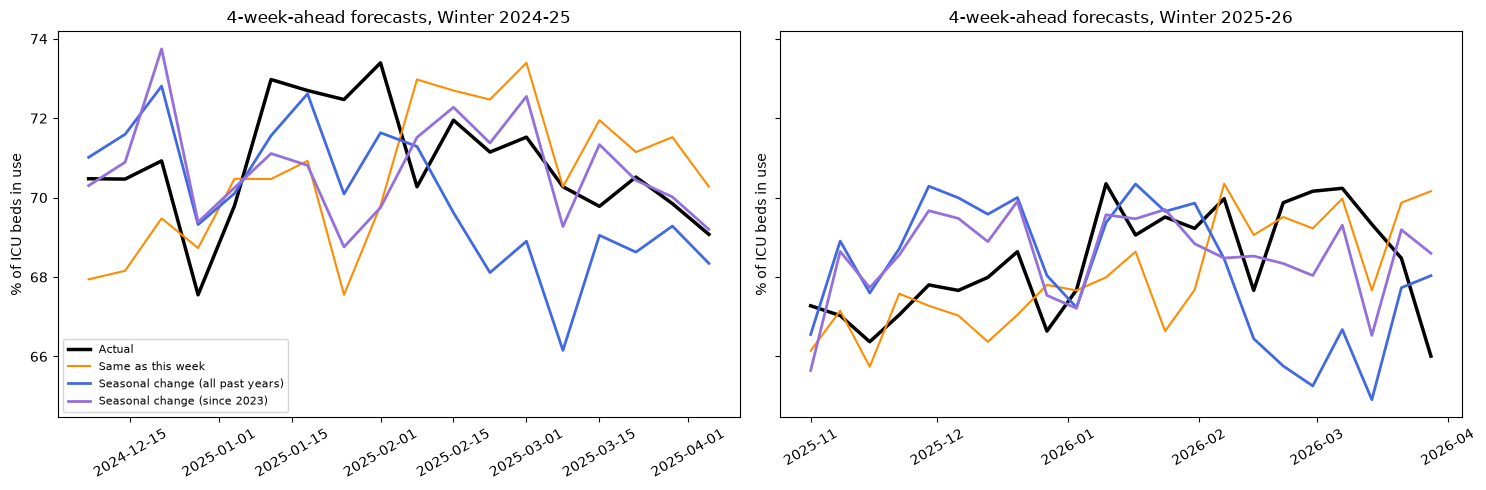

In [4]:
all_results = validation_results(pd.concat([baseline_backtests, seasonal_backtests], ignore_index=True))
four_week = all_results[all_results["horizon_weeks"] == 4]
lines_to_plot = {
    "Same as this week": ("darkorange", 1.5),
    "Seasonal change (all past years)": ("royalblue", 2),
    "Seasonal change (since 2023)": ("mediumpurple", 2),
}
winters = [("2024-11-01", "2025-04-05", "Winter 2024-25"), ("2025-11-01", "2026-03-28", "Winter 2025-26")]

figure, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for axis, (start, end, title) in zip(axes, winters):
    window = four_week[four_week["target_week"].between(start, end)]
    actual = window.drop_duplicates("target_week")
    axis.plot(actual["target_week"], actual["actual_share_pct"], color="black", linewidth=2.5, label="Actual")
    for rule_name, (color, width) in lines_to_plot.items():
        rule_window = window[window["rule"] == rule_name]
        axis.plot(rule_window["target_week"], rule_window["forecast_share_pct"], color=color, linewidth=width, label=rule_name)
    axis.set_title(f"4-week-ahead forecasts, {title}")
    axis.set_ylabel("% of ICU beds in use")
    axis.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Is the improvement real, or could it be luck?
With about 70 forecasts per horizon and two winters, a small improvement can appear by chance. This check compares the approach with "same as this week" week by week, then resamples the weeks in 8-week blocks 4,000 times to see how much the improvement could vary. Blocks are used because neighboring weeks are similar, so treating each week as independent would overstate certainty. If the likely range includes 0, the improvement is not clear.

In [ ]:
all_validation = validation_results(pd.concat([baseline_backtests, seasonal_backtests], ignore_index=True))
print("Seasonal change (since 2023) vs same as this week:")
print(improvement_uncertainty(all_validation, "Seasonal change (since 2023)").to_string())
print()
winter_validation = all_validation[all_validation["target_week"].dt.month.isin([12, 1, 2, 3])]
print("Winter only (December to March), average error in share (points):")
print(
    winter_validation[winter_validation["rule"].isin(["Same as this week", "Seasonal change (since 2023)"])]
    .groupby(["horizon_weeks", "rule"])["error_share_pts"]
    .apply(lambda errors: errors.abs().mean())
    .unstack("rule")
    .round(2)
    .to_string()
)

### Finding: adding the usual seasonal change helps, but only when learned from recent years

**Result**
- Learned from 2023 onward, the seasonal approach beat the best baseline on share at every horizon: by 2% at 1 week, 6% at 2 weeks, 11% at 3 weeks, and 5% at 4 weeks.
- Learned from all past years, including 2020 to 2022, it was worse than the best baseline at every horizon, by 4% to 27%, with the largest gap at 4 weeks.
- In winter (December to March), the 2023-onward version was 15% to 22% more accurate than "same as this week" at every horizon (for example, 1.25 vs 1.61 points at 4 weeks).
- The resampling check shows the overall improvement is not clear: at 3 weeks, the approach was better in 64% of weeks, but the likely range of improvement runs from about 7% worse to 24% better. The ranges at the other horizons also include zero.
- In patients, the all-years version appears better at 1 to 3 weeks despite its worse share forecasts.

**Interpretation**
Adding the typical seasonal change to the current level combines what each baseline does well, and it helps most where "same as this week" is weakest: winter, when the share is rising or falling fastest. The seasonal swings of 2020 to 2022 were much larger than recent ones, so learning from them pushes forecasts too far. For this approach, the COVID-19 years are left out.

The patient comparison disagrees with the share comparison because the bed-count noise found in Notebook 04 is large enough to hide real differences between forecasts. Approaches are therefore chosen on share accuracy.

The approach is a promising candidate, not a proven improvement. With about 70 forecasts and two winters, an improvement of this size cannot be separated from chance.

**Limitation**
Both validation winters were relatively mild. If a surge on the scale of 2021 returned, seasonal changes learned only from recent years would likely underestimate it. The approach also assumes the seasonal pattern repeats on the same calendar weeks, while Notebook 03 showed the peak can shift by several weeks between years.